# Notebook 04 — Formulación y validación de hipótesis (Fases 2 y 6)

**Qué hace este notebook:** convierte las preguntas del notebook 01 en **hipótesis contrastables**, verifica los supuestos de cada prueba, ejecuta los tests y decide con el **valor p** (α = 0,05), reportando también el **tamaño del efecto** (un p muy pequeño con 40.000 pedidos no significa que el efecto importe en la práctica).

**Regla de coherencia:** cada hipótesis se muestra en el video y en el dashboard con *su propio* gráfico. (En la entrega anterior se proyectó una figura que no correspondía a las hipótesis; aquí se evita.)

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Rutas del proyecto (los notebooks viven en /notebooks)
RAIZ = Path('..').resolve()
RAW = RAIZ / 'data' / 'raw' / 'online_retail_II.csv'
PROC = RAIZ / 'data' / 'processed'
FIG = RAIZ / 'docs' / 'figuras'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## 1. Hipótesis

Nivel de significancia: **α = 0,05** para todas. Como son varias pruebas, al final se aplica la corrección de **Holm** para controlar el error tipo I acumulado.

---
### H1 — Estacionalidad (responde P1)
- **H0:** los ingresos semanales en temporada alta (septiembre–noviembre) son iguales a los del resto del año.
- **H1:** los ingresos semanales en temporada alta son **mayores**.
- **Variables:** `fecha` (semana), `importe` (ventas brutas). **Prueba:** Mann-Whitney U unilateral (y t de Welch sobre log como verificación).
- **Por qué importa:** si es cierto, el inventario y el marketing deben concentrarse antes de septiembre. **KPI:** Ingresos netos.

### H2 — Tamaño del pedido por mercado (P5)
- **H0:** el valor del pedido es igual en clientes del Reino Unido y del Exterior.
- **H1:** el valor del pedido **difiere** entre ambos mercados.
- **Variables:** `importe` del pedido, `pais_grupo`. **Prueba:** Mann-Whitney U bilateral (+ t de Welch sobre log).
- **Por qué importa:** decide si vale la pena una estrategia comercial distinta para exportación. **KPI:** Ticket promedio.

### H3 — Devoluciones y mercado (P4, P5)
- **H0:** la proporción de facturas de devolución es la misma en el Reino Unido y en el Exterior (independencia).
- **H1:** la proporción **difiere** entre mercados.
- **Variables:** `tipo` de factura (venta/devolución), `pais_grupo`. **Prueba:** Chi-cuadrado de independencia + V de Cramér.
- **Por qué importa:** si el Exterior devuelve más, hay un problema logístico o de expectativas concentrado ahí. **KPI:** Tasa de devolución.

### H4 — Valor del primer pedido y recompra (P3)
- **H0:** el valor del primer pedido es igual entre quienes recompran en 90 días y quienes no.
- **H1:** quienes recompran en 90 días hicieron un primer pedido de **mayor** valor.
- **Variables:** `importe` del primer pedido, `recompra_90d`. **Prueba:** Mann-Whitney U unilateral + regresión logística (para controlar por otras variables).
- **Por qué importa:** permite identificar desde el primer pedido a los clientes con más potencial. **KPI:** Tasa de recompra a 90 días.

### H5 — Captación en temporada alta y recompra (P1, P3)
- **H0:** la tasa de recompra a 90 días es igual para clientes captados en temporada alta y en el resto del año.
- **H1:** la tasa de recompra **difiere**.
- **Variables:** mes de la primera compra, `recompra_90d`. **Prueba:** Chi-cuadrado + diferencia de proporciones con IC 95 %.
- **Por qué importa:** la temporada alta atrae mucha demanda, pero ¿trae clientes que se quedan? Define dónde invertir en retención. **KPI:** Tasa de recompra.

### H6 — Mercado y recompra (P3, P5)
- **H0:** la tasa de recompra a 90 días es igual en el Reino Unido y en el Exterior.
- **H1:** la tasa de recompra **difiere**.
- **Variables:** `pais_grupo`, `recompra_90d`. **Prueba:** Chi-cuadrado + diferencia de proporciones con IC 95 %.
- **Por qué importa:** si fuera igual, no hace falta un programa de retención específico para exportación.

In [2]:
hipotesis = pd.DataFrame([
    ('H1', 'Ingresos semanales: temporada alta > resto', 'Mann-Whitney U (unilateral)', 'Ingresos netos',           'P1'),
    ('H2', 'Valor del pedido: Reino Unido != Exterior',  'Mann-Whitney U (bilateral)', 'Ticket promedio',          'P5'),
    ('H3', 'Tasa de devolucion: Reino Unido != Exterior', 'Chi-cuadrado + V de Cramer', 'Tasa de devolucion',      'P4, P5'),
    ('H4', 'Primer pedido: recompra > no recompra',        'Mann-Whitney U + logistica', 'Tasa de recompra 90d',    'P3'),
    ('H5', 'Recompra: captados en temporada alta != resto', 'Chi-cuadrado + IC',          'Tasa de recompra 90d',    'P1, P3'),
    ('H6', 'Recompra: Reino Unido != Exterior',            'Chi-cuadrado + IC',          'Tasa de recompra 90d',    'P3, P5'),
], columns=['id', 'hipotesis', 'prueba', 'kpi relacionado', 'pregunta'])
hipotesis

,id,hipotesis,prueba,kpi relacionado,pregunta
0,H1,Ingresos semanales: temporada alta > resto,Mann-Whitney U (unilateral),Ingresos netos,P1
1,H2,Valor del pedido: Reino Unido != Exterior,Mann-Whitney U (bilateral),Ticket promedio,P5
2,H3,Tasa de devolucion: Reino Unido != Exterior,Chi-cuadrado + V de Cramer,Tasa de devolucion,"P4, P5"
3,H4,Primer pedido: recompra > no recompra,Mann-Whitney U + logistica,Tasa de recompra 90d,P3
4,H5,Recompra: captados en temporada alta != resto,Chi-cuadrado + IC,Tasa de recompra 90d,"P1, P3"
5,H6,Recompra: Reino Unido != Exterior,Chi-cuadrado + IC,Tasa de recompra 90d,"P3, P5"


## 2. Tablas de análisis para cada prueba

Cada hipótesis necesita una **unidad de observación distinta**: semana (H1), pedido (H2), factura (H3) y cliente (H4–H6). Se construyen explícitamente para no mezclar niveles.

In [3]:
df = pd.read_parquet(PROC / 'lineas_limpias.parquet')
ventas = df[df['tipo'] == 'Venta']

# --- H1: serie semanal (solo semanas completas y sin el mes incompleto) ---
ventas = ventas.assign(semana=ventas['fecha'].dt.to_period('W-SUN').dt.start_time)
sem = ventas[~ventas['mes_incompleto']].groupby('semana')['importe'].sum().reset_index()
sem = sem[(sem['semana'] >= '2009-12-07') & (sem['semana'] + pd.Timedelta(days=6) <= '2011-11-30')].copy()
sem['mitad_semana'] = sem['semana'] + pd.Timedelta(days=3)
sem['temporada_alta'] = sem['mitad_semana'].dt.month.isin([9, 10, 11])
print(f'{len(sem)} semanas | temporada alta: {sem["temporada_alta"].sum()} | resto: {(~sem["temporada_alta"]).sum()}')

# --- H2: pedidos de venta ---
pedidos = (ventas.groupby('factura')
           .agg(fecha=('fecha_hora', 'min'), pais_grupo=('pais_grupo', 'first'), importe=('importe', 'sum'))
           .reset_index())
pedidos = pedidos[pedidos['importe'] > 0]

# --- H3: todas las facturas (ventas y devoluciones) ---
facturas = df.groupby('factura').agg(tipo=('tipo', 'first'), pais_grupo=('pais_grupo', 'first')).reset_index()

# --- H4-H6: un cliente por fila, con su primer pedido y su recompra a 90 dias ---
ped_cli = (ventas.dropna(subset=['cliente_id']).groupby(['cliente_id', 'factura'])
           .agg(fecha=('fecha', 'min'), importe=('importe', 'sum'), pais_grupo=('pais_grupo', 'first')).reset_index()
           .sort_values(['cliente_id', 'fecha', 'factura']))
ped_cli['n_pedido'] = ped_cli.groupby('cliente_id').cumcount()
primero = ped_cli[ped_cli['n_pedido'] == 0].set_index('cliente_id')
segundo = ped_cli[ped_cli['n_pedido'] == 1].set_index('cliente_id')['fecha']
primero['dias_a_recompra'] = (segundo - primero['fecha']).dt.days

# Solo clientes observables 90 dias: si no, quien compro en nov-2011 "no recompra" por falta de tiempo (censura)
fecha_max = ventas['fecha'].max()
clientes = primero[primero['fecha'] <= fecha_max - pd.Timedelta(days=90)].copy()
clientes['recompra_90d'] = clientes['dias_a_recompra'] <= 90
clientes['captado_temporada_alta'] = clientes['fecha'].dt.month.isin([9, 10, 11])
print(f'{len(clientes):,} clientes observables a 90 dias | recompra a 90d: {clientes["recompra_90d"].mean():.1%}')

101 semanas | temporada alta: 26 | resto: 75


5,256 clientes observables a 90 dias | recompra a 90d: 46.7%


**Por qué se filtran los clientes observables:** un cliente captado el 20 de noviembre de 2011 no tuvo 90 días para recomprar antes de que terminaran los datos. Contarlo como "no recompra" sesgaría la tasa hacia abajo (especialmente para los captados en temporada alta). Solo se incluyen clientes cuya primera compra ocurrió al menos 90 días antes del final de los datos.

## 3. Verificación de supuestos

Antes de elegir la prueba se revisa si los datos cumplen lo que exigiría una prueba paramétrica: **normalidad** y **varianzas parecidas**.

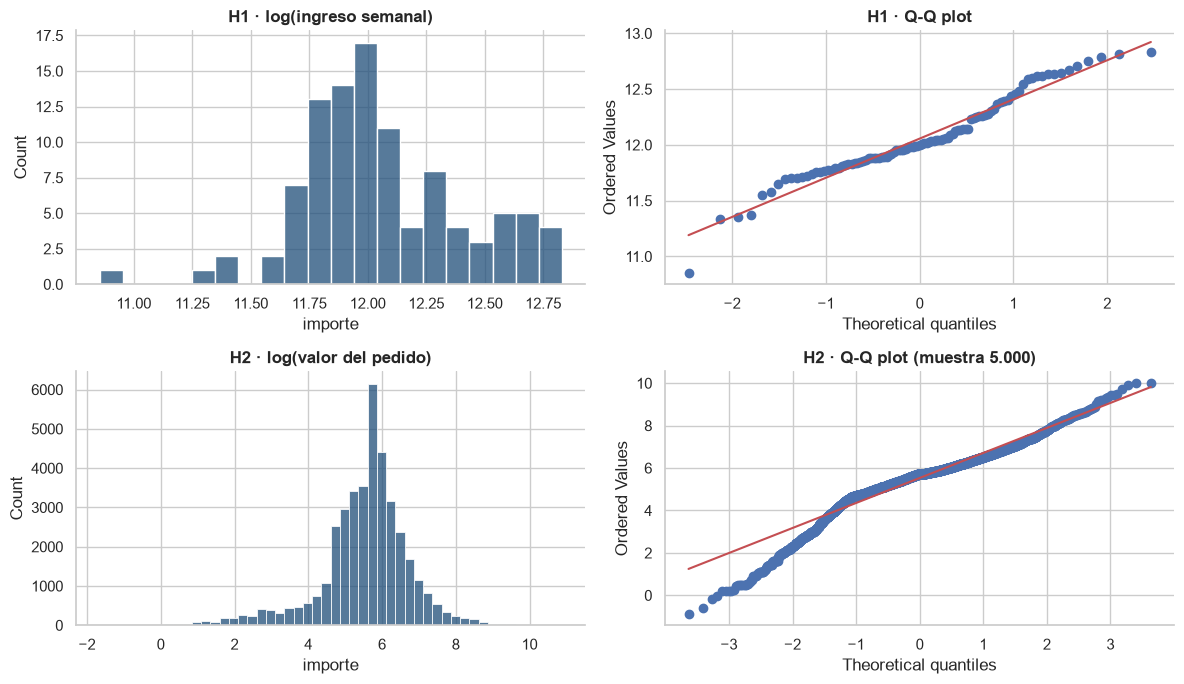

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
log_sem = np.log(sem['importe'])
sns.histplot(log_sem, bins=20, color=AZUL, ax=axs[0, 0]); axs[0, 0].set_title('H1 · log(ingreso semanal)')
stats.probplot(log_sem, dist='norm', plot=axs[0, 1]); axs[0, 1].set_title('H1 · Q-Q plot')
log_ped = np.log(pedidos['importe'])
sns.histplot(log_ped, bins=50, color=AZUL, ax=axs[1, 0]); axs[1, 0].set_title('H2 · log(valor del pedido)')
stats.probplot(log_ped.sample(5000, random_state=1), dist='norm', plot=axs[1, 1]); axs[1, 1].set_title('H2 · Q-Q plot (muestra 5.000)')
plt.tight_layout()
plt.savefig(FIG / '04_supuestos_normalidad.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
sw_alta = stats.shapiro(log_sem[sem['temporada_alta']])
sw_resto = stats.shapiro(log_sem[~sem['temporada_alta']])
lev1 = stats.levene(log_sem[sem['temporada_alta']], log_sem[~sem['temporada_alta']])
ref = pedidos[pedidos['pais_grupo'] == 'Reino Unido']['importe']
ext = pedidos[pedidos['pais_grupo'] == 'Exterior']['importe']
lev2 = stats.levene(np.log(ref), np.log(ext))
dag = stats.normaltest(log_ped)

pd.DataFrame([
    ('H1 · Shapiro-Wilk log(ingreso semanal), temporada alta', sw_alta.statistic, sw_alta.pvalue),
    ('H1 · Shapiro-Wilk log(ingreso semanal), resto',          sw_resto.statistic, sw_resto.pvalue),
    ('H1 · Levene (igualdad de varianzas) en log',              lev1.statistic, lev1.pvalue),
    ('H2 · D\'Agostino-Pearson log(valor del pedido)',         dag.statistic, dag.pvalue),
    ('H2 · Levene (igualdad de varianzas) en log',              lev2.statistic, lev2.pvalue),
], columns=['prueba de supuesto', 'estadistico', 'p-valor']).set_index('prueba de supuesto')

,estadistico,p-valor
prueba de supuesto,,
"H1 · Shapiro-Wilk log(ingreso semanal), temporada alta",0.93,0.09
"H1 · Shapiro-Wilk log(ingreso semanal), resto",0.94,0.00
H1 · Levene (igualdad de varianzas) en log,1.36,0.25
H2 · D'Agostino-Pearson log(valor del pedido),"6,646.82",0.00
H2 · Levene (igualdad de varianzas) en log,0.32,0.57


**Qué se concluye de los supuestos:**
- **Normalidad:** en H1 el log del ingreso semanal es razonablemente normal en temporada alta (Shapiro p = 0,09) pero **no** en el resto del año (p < 0,01); en H2 el log del valor del pedido no es normal (p ≈ 0, esperable con 39.000 datos). → No se puede confiar solo en una prueba t.
- **Varianzas:** Levene no detecta diferencias de varianza en log (p = 0,25 y 0,57). → Welch es seguro.
- **Decisión:** la prueba **principal es Mann-Whitney U** (no exige normalidad) y la **t de Welch sobre el logaritmo** se reporta como verificación. Si ambas coinciden, la conclusión es robusta.
- **Para las proporciones** (H3, H5, H6) se usa chi-cuadrado; las frecuencias esperadas son muy superiores a 5, por lo que se cumple el supuesto.

## 4. Pruebas de hipótesis

Se usan dos funciones auxiliares para el **tamaño del efecto** (el valor p dice *si* hay diferencia; el tamaño del efecto dice *cuánta*):
- **Correlación biserial por rangos** (r): derivada de Mann-Whitney, va de −1 a 1 (0,1 pequeño · 0,3 mediano · 0,5 grande).
- **IC bootstrap** de la diferencia de medianas: intervalo de confianza sin suponer normalidad.

In [6]:
def biserial_rangos(x, y):
    """Tamano del efecto de Mann-Whitney: P(x > y) - P(x < y)."""
    u = stats.mannwhitneyu(x, y, alternative='two-sided').statistic
    return 2 * u / (len(x) * len(y)) - 1

def ic_dif_medianas(x, y, n=2000, seed=42):
    rng = np.random.default_rng(seed)
    x, y = np.asarray(x), np.asarray(y)
    difs = [np.median(rng.choice(x, len(x))) - np.median(rng.choice(y, len(y))) for _ in range(n)]
    return np.percentile(difs, [2.5, 97.5])

resultados = []   # aqui se acumulan p-valores para la tabla final (Holm)

### H1 — ¿Los ingresos semanales son mayores en temporada alta?

Mediana semanal  temporada alta: £260,999  |  resto: £154,864  (x1.69)
Mann-Whitney U (unilateral): U = 1,717, p = 4.22e-09
t de Welch sobre log (unilateral): t = 7.43, p = 2.39e-09
Tamano del efecto (biserial por rangos): r = 0.76
IC95% de la diferencia de medianas: £68,785 a £151,158


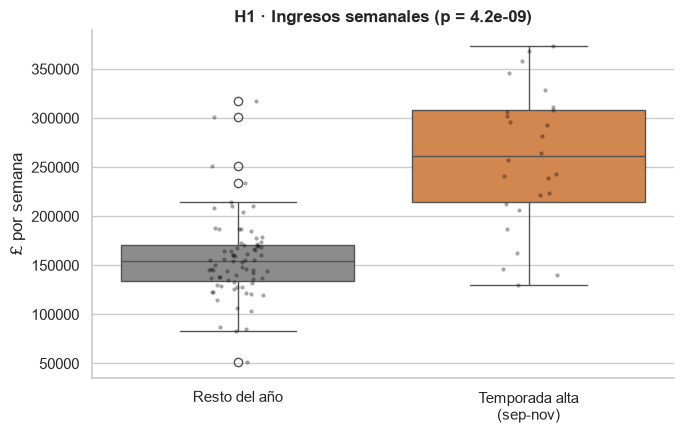

In [7]:
alta = sem.loc[sem['temporada_alta'], 'importe']
resto = sem.loc[~sem['temporada_alta'], 'importe']

mw = stats.mannwhitneyu(alta, resto, alternative='greater')
tw = stats.ttest_ind(np.log(alta), np.log(resto), equal_var=False, alternative='greater')
r_h1 = biserial_rangos(alta, resto)
ic = ic_dif_medianas(alta, resto)

print(f'Mediana semanal  temporada alta: £{alta.median():,.0f}  |  resto: £{resto.median():,.0f}  (x{alta.median()/resto.median():.2f})')
print(f'Mann-Whitney U (unilateral): U = {mw.statistic:,.0f}, p = {mw.pvalue:.2e}')
print(f't de Welch sobre log (unilateral): t = {tw.statistic:.2f}, p = {tw.pvalue:.2e}')
print(f'Tamano del efecto (biserial por rangos): r = {r_h1:.2f}')
print(f'IC95% de la diferencia de medianas: £{ic[0]:,.0f} a £{ic[1]:,.0f}')
resultados.append(('H1', 'Mann-Whitney (unilateral)', mw.pvalue, r_h1, 'r biserial'))

fig, ax = plt.subplots(figsize=(7, 4.5))
datos = sem.assign(grupo=np.where(sem['temporada_alta'], 'Temporada alta\n(sep-nov)', 'Resto del año'))
sns.boxplot(data=datos, x='grupo', y='importe', palette=[GRIS, NARANJA], order=['Resto del año', 'Temporada alta\n(sep-nov)'], ax=ax)
sns.stripplot(data=datos, x='grupo', y='importe', color='black', alpha=.35, size=3, order=['Resto del año', 'Temporada alta\n(sep-nov)'], ax=ax)
ax.set_title(f'H1 · Ingresos semanales (p = {mw.pvalue:.1e})'); ax.set_xlabel(''); ax.set_ylabel('£ por semana')
plt.tight_layout()
plt.savefig(FIG / '04_h1_estacionalidad.png', dpi=150, bbox_inches='tight')
plt.show()

**Decisión H1: se rechaza H0 (p ≈ 4×10⁻⁹ < 0,05).**
La mediana semanal en temporada alta es **£261.000** frente a **£155.000** el resto del año (**×1,69**). El tamaño del efecto es **grande** (r = 0,76) y el IC 95 % de la diferencia de medianas es £69.000–£151.000 por semana. La t de Welch sobre el log coincide (p ≈ 2×10⁻⁹).

**Cautela:** las semanas consecutivas no son totalmente independientes y solo hay dos temporadas altas (2010 y 2011). Aun así, el patrón se repite en ambos años (ver notebook 03), por lo que la conclusión es sólida.

### H2 — ¿El valor del pedido difiere entre Reino Unido y Exterior?

Mediana del pedido  Reino Unido: £295 (n=36,182)  |  Exterior: £421 (n=3,332)
Mann-Whitney U (bilateral): p = 8.66e-145
t de Welch sobre log: t = -25.80, p = 5.95e-136
Tamano del efecto (biserial por rangos, Exterior vs RU): r = 0.27
IC95% de la diferencia de medianas (Exterior - RU): £108 a £146


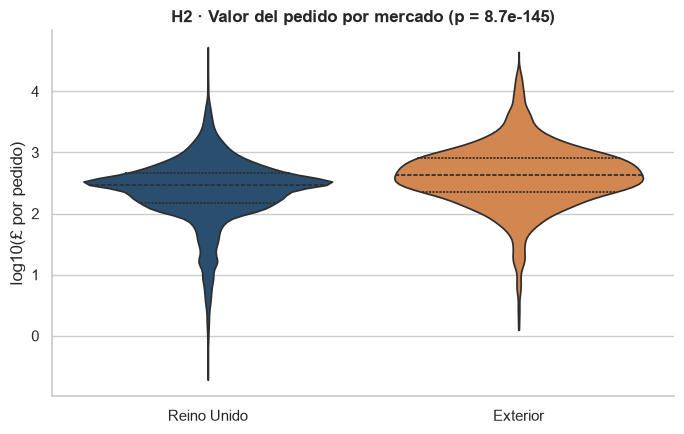

In [8]:
mw = stats.mannwhitneyu(ref, ext, alternative='two-sided')
tw = stats.ttest_ind(np.log(ref), np.log(ext), equal_var=False)
r_h2 = biserial_rangos(ext, ref)         # positivo = el Exterior tiende a pedidos mayores
ic = ic_dif_medianas(ext, ref)

print(f'Mediana del pedido  Reino Unido: £{ref.median():,.0f} (n={len(ref):,})  |  Exterior: £{ext.median():,.0f} (n={len(ext):,})')
print(f'Mann-Whitney U (bilateral): p = {mw.pvalue:.2e}')
print(f't de Welch sobre log: t = {tw.statistic:.2f}, p = {tw.pvalue:.2e}')
print(f'Tamano del efecto (biserial por rangos, Exterior vs RU): r = {r_h2:.2f}')
print(f'IC95% de la diferencia de medianas (Exterior - RU): £{ic[0]:,.0f} a £{ic[1]:,.0f}')
resultados.append(('H2', 'Mann-Whitney (bilateral)', mw.pvalue, r_h2, 'r biserial'))

fig, ax = plt.subplots(figsize=(7, 4.5))
datos = pedidos.assign(logimp=np.log10(pedidos['importe']))
sns.violinplot(data=datos, x='pais_grupo', y='logimp', hue='pais_grupo', order=['Reino Unido', 'Exterior'], palette=[AZUL, NARANJA], inner='quartile', cut=0, legend=False, ax=ax)
ax.set_title(f'H2 · Valor del pedido por mercado (p = {mw.pvalue:.1e})'); ax.set_xlabel(''); ax.set_ylabel('log10(£ por pedido)')
plt.tight_layout()
plt.savefig(FIG / '04_h2_ticket_mercado.png', dpi=150, bbox_inches='tight')
plt.show()

**Decisión H2: se rechaza H0 (p ≈ 10⁻¹⁴⁵).**
El pedido mediano del Exterior es **£421** frente a **£295** del Reino Unido (+£108 a +£146 por pedido, IC 95 %). El efecto es **pequeño a mediano** (r = 0,27): si se compara un pedido del Exterior con uno del Reino Unido al azar, el del Exterior es mayor unas 63 de cada 100 veces (r = P(Exterior mayor) − P(Reino Unido mayor) = 0,27).

**Lectura de negocio:** los clientes del exterior compran menos veces (3.332 pedidos frente a 36.182) pero con pedidos más grandes. Un p-valor tan extremo es consecuencia del tamaño de muestra; lo que importa para la decisión es el efecto: **+43 % en la mediana**.

### H3 — ¿La proporción de devoluciones difiere entre mercados?

tipo         Devolucion  Venta
pais_grupo                    
Exterior            811   3332
Reino Unido        6593  36182

Proporcion de facturas de devolucion:
pais_grupo
Exterior      0.20
Reino Unido   0.15

Chi-cuadrado = 48.9, gl = 1, p = 2.67e-12 | V de Cramer = 0.032
Frecuencia esperada minima: 654 (supuesto chi-cuadrado: >= 5)


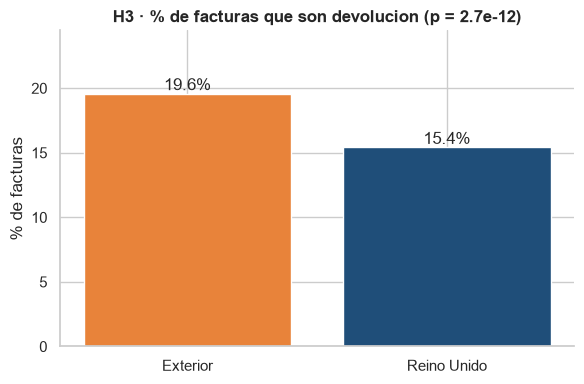

In [9]:
tabla = pd.crosstab(facturas['pais_grupo'], facturas['tipo'])
chi2, p3, gl, esperado = stats.chi2_contingency(tabla)
n = tabla.values.sum()
cramer = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
prop = tabla['Devolucion'] / tabla.sum(axis=1)

print(tabla)
print(f'\nProporcion de facturas de devolucion:\n{prop.round(4).to_string()}')
print(f'\nChi-cuadrado = {chi2:.1f}, gl = {gl}, p = {p3:.2e} | V de Cramer = {cramer:.3f}')
print(f'Frecuencia esperada minima: {esperado.min():.0f} (supuesto chi-cuadrado: >= 5)')
resultados.append(('H3', 'Chi-cuadrado', p3, cramer, 'V de Cramer'))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(prop.index, prop.values * 100, color=[NARANJA, AZUL])
for i, v in enumerate(prop.values * 100):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')
ax.set_title(f'H3 · % de facturas que son devolucion (p = {p3:.1e})'); ax.set_ylabel('% de facturas')
ax.set_ylim(0, prop.max() * 100 * 1.25)
plt.tight_layout()
plt.savefig(FIG / '04_h3_devoluciones_mercado.png', dpi=150, bbox_inches='tight')
plt.show()

**Decisión H3: se rechaza H0 (p ≈ 3×10⁻¹²), pero el efecto es trivial.**
El **19,6 %** de las facturas del Exterior son devoluciones frente al **15,4 %** del Reino Unido. Sin embargo, la V de Cramér es **0,032** (muy por debajo de 0,1): el país explica una parte minúscula de la variación en devoluciones.

**Este es el ejemplo de por qué no basta el p-valor:** con ~47.000 facturas cualquier diferencia mínima sale "significativa". La conclusión responsable es que **existe una diferencia real pero pequeña**; en valor, la diferencia es 3,0 % vs 2,3 % (notebook 05). No justifica por sí sola una intervención costosa.

### H4 — ¿Quienes recompran en 90 días hicieron un primer pedido mayor?

In [10]:
si = clientes.loc[clientes['recompra_90d'], 'importe']
no = clientes.loc[~clientes['recompra_90d'], 'importe']

mw = stats.mannwhitneyu(si, no, alternative='greater')
r_h4 = biserial_rangos(si, no)
ic = ic_dif_medianas(si, no)
print(f'Mediana del primer pedido  recompra: £{si.median():,.0f} (n={len(si):,}) | no recompra: £{no.median():,.0f} (n={len(no):,})')
print(f'Mann-Whitney U (unilateral): p = {mw.pvalue:.2e} | r biserial = {r_h4:.2f}')
print(f'IC95% de la diferencia de medianas: £{ic[0]:,.0f} a £{ic[1]:,.0f}')
resultados.append(('H4', 'Mann-Whitney (unilateral)', mw.pvalue, r_h4, 'r biserial'))

Mediana del primer pedido  recompra: £313 (n=2,457) | no recompra: £253 (n=2,799)
Mann-Whitney U (unilateral): p = 9.16e-30 | r biserial = 0.18
IC95% de la diferencia de medianas: £46 a £72


In [11]:
# Regresion logistica: el efecto del primer pedido, controlando por mercado y temporada de captacion
import statsmodels.formula.api as smf

mod = clientes.reset_index().assign(
    log_primer_pedido=lambda d: np.log(d['importe']),
    exterior=lambda d: (d['pais_grupo'] == 'Exterior').astype(int),
    temporada_alta=lambda d: d['captado_temporada_alta'].astype(int),
    recompra=lambda d: d['recompra_90d'].astype(int))
logit = smf.logit('recompra ~ log_primer_pedido + exterior + temporada_alta', data=mod).fit(disp=0)

coef = pd.DataFrame({'odds ratio': np.exp(logit.params), 'IC95% inf': np.exp(logit.conf_int()[0]),
                     'IC95% sup': np.exp(logit.conf_int()[1]), 'p-valor': logit.pvalues})
print(f'Pseudo R2 de McFadden: {logit.prsquared:.3f}')
coef.round(3)

Pseudo R2 de McFadden: 0.019


,odds ratio,IC95% inf,IC95% sup,p-valor
Intercept,0.12,0.08,0.18,0.00
log_primer_pedido,1.44,1.34,1.54,0.00
exterior,0.82,0.67,1.00,0.04
temporada_alta,0.72,0.62,0.82,0.00


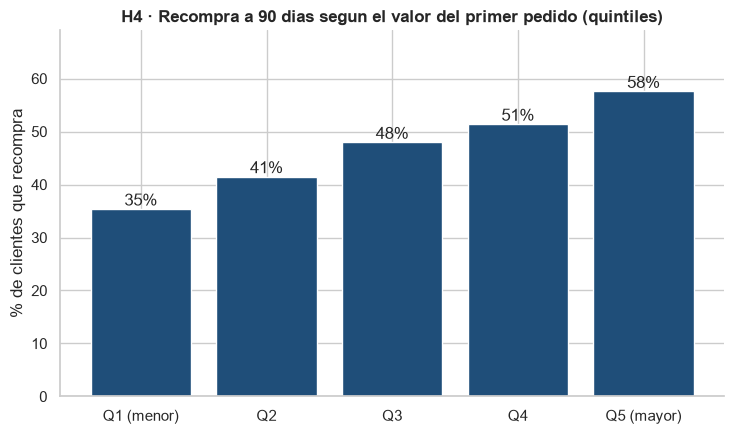

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
cl = clientes.reset_index()
cl['tramo'] = pd.qcut(cl['importe'], 5, labels=['Q1 (menor)', 'Q2', 'Q3', 'Q4', 'Q5 (mayor)'])
tasa = cl.groupby('tramo', observed=True)['recompra_90d'].mean() * 100
ax.bar(tasa.index.astype(str), tasa.values, color=AZUL)
for i, v in enumerate(tasa.values):
    ax.text(i, v, f'{v:.0f}%', ha='center', va='bottom')
ax.set_title('H4 · Recompra a 90 dias segun el valor del primer pedido (quintiles)')
ax.set_ylabel('% de clientes que recompra'); ax.set_ylim(0, tasa.max() * 1.2)
plt.tight_layout()
plt.savefig(FIG / '04_h4_primer_pedido_recompra.png', dpi=150, bbox_inches='tight')
plt.show()

**Decisión H4: se rechaza H0 (p ≈ 10⁻²⁹).**
Los clientes que recompran en 90 días hicieron un primer pedido de mediana **£313** frente a **£253** de quienes no recompran (+£46 a +£72, IC 95 %). Efecto **pequeño** (r = 0,18).

**Regresión logística (controlando mercado y temporada):**
- Cada vez que el primer pedido se multiplica por *e* (≈ 2,7), las **probabilidades relativas (odds) de recomprar suben un 44 %** (OR = 1,44; IC 1,34–1,54).
- Haber sido captado en temporada alta **baja las odds un 28 %** (OR = 0,72; IC 0,62–0,82).
- El modelo explica poco (pseudo-R² = 0,019): **el valor del primer pedido es una pista, no un predictor fuerte**. No hay que tomar decisiones individuales de clientes con él.